# 04 · External training photos

**Why.** 66 photos are few; several kinds of scene appear only once (a closed wheelie bin, a single dirty bowl next to a
clean sink). Adding real photos of the missing scene types is the change that helped most.

**Rules for an external photo.**
1. A stated licence that allows use (Unsplash, Pexels, Pixabay, Creative Commons) — or the author's own photo.
   Photos with no verifiable licence (e.g. Pinterest saves) are only used for comparison, never in the final model.
2. Not a copy of a competition photo. The competition photos come from Unsplash and Pexels, so many stock photos are
   the very same pictures. Every new photo is compared with all 102 competition photos (DINOv2 cosine similarity;
   ≥ 0.90 = same photo) and dropped if it matches. This caught 13 copies, three of them **test** photos
   (#36, #70, #71), which are not in `data/external.csv`.
3. Labelled by the photo, not by what helps the score (e.g. #913 has a mug in the sink → *Incomplete*).

Sources and licences of all photos: `data/external.csv`; the photos used in the final model are also stored, sorted by
label and scene type, with `CREDITS.csv`, in `data/images/external/`.

In [1]:
import numpy as np, pandas as pd
import common as c
pd.set_option('display.width', 200)

In [2]:
e = c.external()
e.groupby(["group", "in_final"]).agg(photos=("id", "size"), labels=("label", lambda s: ", ".join(sorted(set(s)))),
                                     licences=("licence", lambda s: ", ".join(sorted(set(s))))).reset_index()

,group,in_final,photos,labels,licences
0,clean_sinks,True,5,"Washing Dishes|Complete, Washing Dishes|Incomp...","CC BY 2.0, CC BY-SA 4.0, Unsplash License"
1,closed_bins,True,4,Taking Out Trash|Complete,Pexels License
2,first_clean_sink,True,1,Washing Dishes|Complete,Unsplash License
3,licensed_dishes,True,7,"Washing Dishes|Complete, Washing Dishes|Incomp...","Pexels License, Unsplash License"
4,open_bags,True,5,Taking Out Trash|Incomplete,Unsplash License
5,overflowing_bins,True,6,Taking Out Trash|Incomplete,"Pixabay Content License, Unsplash License"
6,own_photos,True,4,"Washing Dishes|Complete, Washing Dishes|Incomp...",Own photo (author's copyright)
7,pexels_dirty_plates,False,2,Washing Dishes|Incomplete,Pexels License
8,pinterest_unverified,False,32,"Taking Out Trash|Complete, Taking Out Trash|In...",unverified (Pinterest save)
9,tied_bags,True,7,Taking Out Trash|Complete,"CC BY-NC-SA 2.0, CC BY-SA 2.0, CC BY-SA 3.0, C..."


In [3]:
dup = c.duplicate_check(e.id.tolist())
print("most similar competition photo for any kept external photo:", dup.cosine.max())
dup.sort_values("cosine", ascending=False).head(5)

most similar competition photo for any kept external photo: 0.89


,id,nearest,cosine,duplicate
38,977,#12 (train),0.890,False
36,975,#12 (train),0.880,False
41,980,#12 (train),0.854,False
39,978,#12 (train),0.852,False
37,976,#12 (train),0.850,False


## What each group adds

Features and classifier are those of the final model (DINOv2 + the two helpers of notebook 05, RBF SVM, with logistic
regression for comparison). Groups are added one at a time, in the order they were collected.

In [4]:
NOV15 = ["tied_bags", "open_bags", "overflowing_bins", "first_clean_sink"]
steps = [
    ("66 competition photos only", []),
    ("+ 19 bag / bin / sink photos", NOV15),
    ("+ 7 licensed dishes photos", NOV15 + ["licensed_dishes"]),
    ("+ 4 closed wheelie bins", NOV15 + ["licensed_dishes", "closed_bins"]),
    ("+ 4 own photos", NOV15 + ["licensed_dishes", "closed_bins", "own_photos"]),
    ("+ 5 clean sinks  (= final set)", NOV15 + ["licensed_dishes", "closed_bins", "own_photos", "clean_sinks"]),
]
models = ("RBF SVM", "logistic regression")
res, wrong = [], {}
for name, groups in steps:
    df = c.training_set(groups)
    r, P = c.cross_validate(df, c.final_features(df.id), models, name=name)
    res.append(r.assign(photos=len(df)))
    wrong[name] = c.wrong_counts(df, P["RBF SVM"])
res = pd.concat(res)
res[res.model == "RBF SVM"].drop(columns="model")

,experiment,CV macro F1,std,dishes F1,trash F1,photos
0,66 competition photos only,0.842,0.016,0.848,0.838,66
0,+ 19 bag / bin / sink photos,0.895,0.019,0.865,0.924,85
0,+ 7 licensed dishes photos,0.905,0.021,0.893,0.917,92
0,+ 4 closed wheelie bins,0.912,0.017,0.893,0.931,96
0,+ 4 own photos,0.905,0.009,0.879,0.931,100
0,+ 5 clean sinks (= final set),0.912,0.013,0.893,0.931,105


Photos the RBF SVM gets wrong (times out of 10) at each step:

In [5]:
pd.DataFrame(wrong).fillna(0).astype(int)

,66 competition photos only,+ 19 bag / bin / sink photos,+ 7 licensed dishes photos,+ 4 closed wheelie bins,+ 4 own photos,+ 5 clean sinks (= final set)
#2,3,8,7,7,1,0
#12,10,3,3,3,10,0
#19,10,0,0,0,0,0
#26,10,10,10,10,10,10
#31,10,10,10,10,10,10
#40,6,0,0,0,0,0
#41,10,0,0,0,0,0
#46,1,1,1,1,0,0
#53,1,0,0,0,0,0
#60,10,10,10,10,10,10


## Checks on the final set

In [6]:
final = c.training_set(final=True)
FINAL_GROUPS = list(c.external()[c.external().in_final].group.unique())
checks = [
    ("final set", final),
    ("final, but #913 labelled Complete", c.training_set(final=True, relabel={913: "Washing Dishes|Complete"})),
    ("final without the 19 bag / bin / sink photos", c.training_set(["licensed_dishes", "closed_bins", "own_photos", "clean_sinks"])),
    ("final + 32 Pinterest photos (licence unverified)", c.training_set(FINAL_GROUPS + ["pinterest_unverified"])),
    ("final + 2 Pexels dirty plates", c.training_set(FINAL_GROUPS + ["pexels_dirty_plates"])),
]
pd.concat([c.cross_validate(df, c.final_features(df.id), models, name=n)[0].assign(photos=len(df)) for n, df in checks])

,experiment,model,CV macro F1,std,dishes F1,trash F1,photos
0,final set,RBF SVM,0.912,0.013,0.893,0.931,105
1,final set,logistic regression,0.895,0.016,0.889,0.904,105
0,"final, but #913 labelled Complete",RBF SVM,0.924,0.012,0.917,0.931,105
1,"final, but #913 labelled Complete",logistic regression,0.912,0.014,0.921,0.904,105
0,final without the 19 bag / bin / sink photos,RBF SVM,0.844,0.013,0.873,0.815,86
1,final without the 19 bag / bin / sink photos,logistic regression,0.844,0.012,0.875,0.813,86
0,final + 32 Pinterest photos (licence unverified),RBF SVM,0.908,0.013,0.921,0.897,137
1,final + 32 Pinterest photos (licence unverified),logistic regression,0.928,0.012,0.924,0.933,137
0,final + 2 Pexels dirty plates,RBF SVM,0.910,0.016,0.893,0.929,107
1,final + 2 Pexels dirty plates,logistic regression,0.897,0.019,0.891,0.904,107


The own photos (3 dirty bowls next to a clean sink, 1 the same bowl cleaned) and the 5 clean sinks:

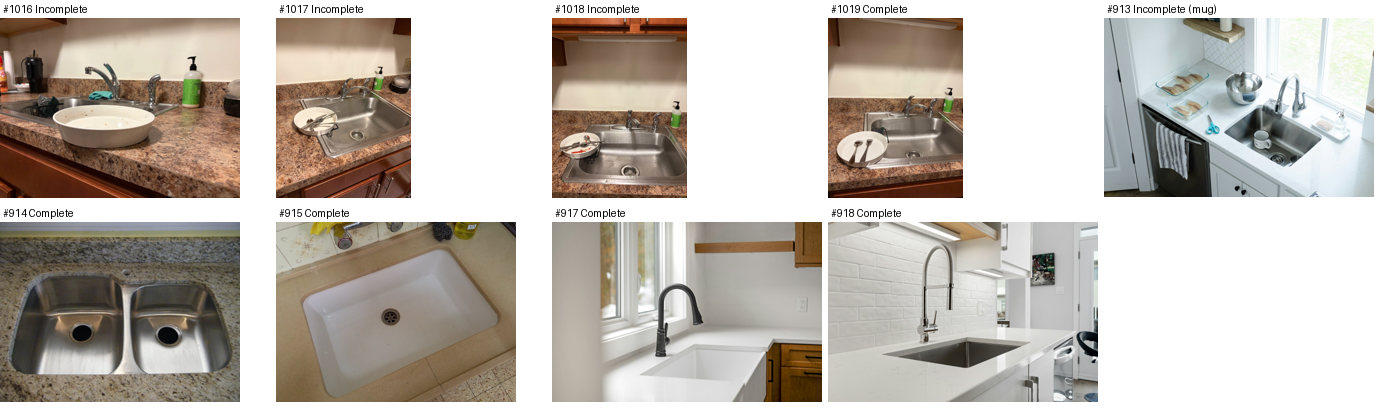

In [7]:
c.show([1016, 1017, 1018, 1019, 913, 914, 915, 917, 918], ["Incomplete"] * 3 + ["Complete", "Incomplete (mug)"] + ["Complete"] * 4, cols=5)

**Result.**
- The 19 bag / bin photos carry the trash classes: 0.842 → 0.895, and without them trash F1 drops from 0.931 to 0.815.
- 7 licensed dishes photos and 4 closed wheelie bins add about +0.01 each (the bins fixed #63).
- The own photos fixed #2, but, being 3 dirty to 1 clean shot of the same sink, made the model call the clean sink
  close-up #12 dirty (0.905); the 5 licensed clean sinks balance that (0.912, #2 and #12 both right).
- #913 is labelled *Incomplete* (a mug is in the sink). Labelling it *Complete* scores higher (0.924), because the host
  labels a similar scene (#101) Complete, but the label follows the photo.
- The 32 Pinterest photos raise logistic regression to 0.928 but lower the SVM; they are not used (licence unverified).